# Scoring experiments
> Compare sampling strategies with the definitions of `07_scoring.ipynb`

Each comparison runs many campaigns and takes up to a minute. The leading underscore keeps this notebook out of `nbdev-test` and the docs: run it by hand, and record results in `scoring-plan.md`. The first cell runs the code cells of `07_scoring.ipynb`, lessons included, to load its definitions.

In [ ]:
from fastcore.nbio import read_nb
for c in read_nb('07_scoring.ipynb').cells:
    if c.cell_type == 'code': get_ipython().run_cell(c.source, silent=True).raise_error()

## Baseline comparison

In [ ]:
strategies = {'equal': equal(), 'prior only': mcdm(fname_raster, [PriorCB(fname_raster)], [True], [1]),
              'max only': mcdm(fname_raster, [MaxCB()], [True], [1]), 'std only': mcdm(fname_raster, [StdCB()], [True], [1]),
              'how-to': mcdm(fname_raster), 'neyman': neyman(), 'oracle': oracle(fname_raster)}
cmp = compare(campaign, strategies, budgets=[150] * 6, seeds=range(5))


Mean Wasserstein distance over units, averaged over seeds, by round:

In [ ]:
cmp.groupby(['strategy', 'round']).mean_wasserstein.mean().unstack().round(4)

## Minimum number of samples

Five strategies under four minimums, three seeds each: no minimum, one sample per unit in every round, and one or two samples per unit over the whole campaign:

In [ ]:
factories = {'equal': equal, 'how-to': lambda m: mcdm(fname_raster, min=m),
             'std only': lambda m: mcdm(fname_raster, [StdCB()], [True], [1], min=m),
             'neyman': neyman, 'oracle': lambda m: oracle(fname_raster, min=m)}
minimums = {'none': lambda f: f(0), '1 per round': lambda f: f(1),
            '1 in total': lambda f: cumulative_min(f(0), 1), '2 in total': lambda f: cumulative_min(f(0), 2)}
cmp_min = pd.concat({name: compare(campaign, {k: make(f) for k, f in factories.items()}, budgets=[150] * 6, seeds=range(3))
                     for name, make in minimums.items()}, names=['minimum'])

Mean Wasserstein distance after round 6, averaged over seeds:

In [ ]:
cmp_min.xs(6, level='round').groupby(['strategy', 'minimum']).mean_wasserstein.mean().unstack()[list(minimums)].round(4)

Without a minimum per round, the oracle improves, and every strategy that estimates from the samples gets worse. `std only` is the extreme case: `StdCB` gives a unit with one sample a standard deviation of 0, and the strategy never chooses that unit again. With a minimum of 1 in total and seed 0, 25 units still have a single sample after six rounds.

## Decision score

With a permissible level of 0.8 and 10% accepted, 35 of the 100 units should be restricted. The raster is smooth: only 9 units have between 2% and 30% of their cells above the level, so few decisions are close. The strategies of the baseline comparison, one sample per unit per round, 5 seeds:

In [ ]:
dcampaign = Campaign(fname_raster, gdf_grid, score=decisions)
test_eq((dcampaign.score(campaign.samples.iloc[:0], dcampaign.truth).true_action == 'restrict').sum(), 35)
cmp_dec = compare(dcampaign, strategies, budgets=[150] * 6, seeds=range(5), summary=summarise_decisions)

Wrong decisions (needless plus missed), averaged over seeds, by round:

In [ ]:
cmp_dec.groupby(['strategy', 'round']).wrong.mean().unstack()

After six rounds, every strategy gets between 2.6 and 4.2 of the 100 decisions wrong, mostly missed restrictions, and the standard deviation over seeds reaches 2.7. Most differences are within that noise. The how-to strategy no longer trails equal allocation, and is ahead of it in rounds 2 and 3. With only 9 close units, this raster cannot separate the strategies. The `oracle` here targets the true standard deviation, not the decisions.

## Decision-aware strategies

Five strategies on two ground truths, 20 seeds each, 6 rounds of 150 samples. Every strategy gets a minimum of one sample per unit over the whole campaign, like the dashboard's minimum number of samples set to 1, and targets the rest freely. `ground-truth-01` at a permissible level of 0.8 has 35 units to restrict and 9 near the boundary (between 2% and 30% of cells above the level). `ground-truth-02` at 0.473 has 48 units to restrict and 32 near the boundary. The accepted proportion is 10%:

In [ ]:
from functools import partial

In [ ]:
def decision_strategies(fname, level, accepted=0.1):
    "The five strategies, each with a minimum of one sample per unit over the campaign."
    return {name: cumulative_min(s, 1) for name, s in {
        'equal': equal(0), 'how-to': mcdm(fname, min=0), 'neyman': neyman(0),
        'bayes': bayes(level, accepted, 0), 'oracle': decision_oracle(fname, level, accepted, 0)}.items()}

f02 = 'files/ground-truth-02-4326-simulated.tif'
truths = {'gt-01 at 0.8': (fname_raster, gdf_grid, 0.8), 'gt-02 at 0.473': (f02, gridder(f02, nrows=10, ncols=10), 0.473)}
cmp_bayes = pd.concat({name: compare(Campaign(f, g, score=partial(decisions, level=l)), decision_strategies(f, l),
                                     budgets=[150] * 6, seeds=range(20), summary=summarise_decisions)
                       for name, (f, g, l) in truths.items()}, names=['truth'])

Wrong decisions, averaged over seeds, by round:

In [ ]:
cmp_bayes.groupby(['truth', 'strategy', 'round']).wrong.mean().unstack().round(1)

With decisions as the score, the strategies separate. After round 6, `bayes` beats equal allocation on both ground truths (2.5 against 3.2 wrong decisions on `gt-01`, 7.8 against 10.0 on `gt-02`), the how-to strategy lies between them, and Neyman allocation is no better than equal. The decision oracle is best (1.4 and 6.5), which leaves room for a better information layer. The standard deviation over seeds is up to 3.2, so the standard error of each mean is below 0.8. The oracle on `gt-02` gets worse from round 2 (6.6) to round 3 (9.0). The dashboard's rule causes it: with 10% accepted, the 10th sample raises the number of exceedances needed to restrict from 1 to 2. For a unit whose true share is 12%, the probability of a wrong decision is 32% with 9 samples and 66% with 10:

In [ ]:
{n: round(float(binom.cdf(np.floor(0.1 * n), n, 0.12)), 3) for n in range(5, 13)}

## Fukushima windows

For internal checks only: these windows come from the 2011 Fukushima air dose raster in `_data`, which git ignores, and nothing derived from them is to be published. The values are log10 of the air dose rate in µSv/h. Each window is a 10 km square, cut into a 10 x 10 grid of 1 km units: one near the plant on the land side, one in the north-west plume around Iitate, and one far to the south-west. None has missing cells. `cut_window` writes them to `_data/windows` as dose rates in µSv/h. `LINEAR1`, which the how-to strategy uses, rejects negative values, and the log10 of any dose rate below 1 µSv/h is negative:

In [ ]:
import os, rasterio
from rasterio.windows import from_bounds
from pyproj import Transformer

In [ ]:
def cut_window(src_path, dst_path, cx, cy, half=5000):
    "Write the square of `src_path` centred on (`cx`, `cy`), `2 * half` metres wide, to `dst_path`, as 10 to the power of its values."
    with rasterio.open(src_path) as src:
        w = from_bounds(cx - half, cy - half, cx + half, cy + half, src.transform)
        prof = src.profile | dict(height=int(w.height), width=int(w.width), transform=src.window_transform(w))
        with rasterio.open(dst_path, 'w', **prof) as dst: dst.write(10 ** src.read(1, window=w), 1)

to_utm = Transformer.from_crs('EPSG:4326', 'EPSG:32654', always_xy=True)
centres = {'near plant': (493911, 4141589), 'nw plume': to_utm.transform(140.73, 37.68), 'far sw': to_utm.transform(140.45, 37.30)}
os.makedirs('../_data/windows', exist_ok=True)
wins = {}
for name, (cx, cy) in centres.items():
    wins[name] = f"../_data/windows/{name.replace(' ', '_')}.tif"
    cut_window('../_data/airdose_all_2011.tif', wins[name], cx, cy)

Two permissible levels per window: the 75th and 90th percentiles of its values near the plant, and the 50th and 75th in the other two, where the 90th leaves few units near the boundary. Units near the boundary have between 2% and 30% of their cells above the level: 6 and 9 near the plant (levels 1.17 and 1.48 in log10 of µSv/h), 23 and 16 in the plume (0.69 and 0.74), 10 and 13 far to the south-west (-0.67 and -0.58). The runs use the same levels in µSv/h. The same five strategies as above, 20 seeds:

In [ ]:
levels = {'near plant': (1.17, 1.48), 'nw plume': (0.69, 0.74), 'far sw': (-0.67, -0.58)}
cmp_fk = {}
for name, path in wins.items():
    g = gridder(path, nrows=10, ncols=10)
    for l in levels[name]:
        lvl = 10 ** l
        cmp_fk[f'{name} at {lvl:.3g}'] = compare(Campaign(path, g, score=partial(decisions, level=lvl)), decision_strategies(path, lvl),
                                                 budgets=[150] * 6, seeds=range(20), summary=summarise_decisions)
cmp_fk = pd.concat(cmp_fk, names=['truth'])

Wrong decisions after round 6, averaged over seeds:

In [ ]:
cmp_fk.xs(6, level='round').groupby(['truth', 'strategy']).wrong.mean().unstack().round(1)

`bayes` makes fewer wrong decisions than equal allocation in all six settings. The gap is clear far to the south-west (1.4 against 3.3 at 0.214, 2.2 against 3.2 at 0.263) and within about two standard errors elsewhere; standard errors of the means range from 0.1 to 0.6. It beats the how-to strategy in five settings; near the plant at 30.2 the how-to strategy does better (1.8 against 2.4). The oracle is best everywhere, with the largest gaps near the plant and in the plume at 5.5 (2.8 against 4.8). Neyman allocation is the worst or close to it. No significant negative Moran's I stopped `LINEAR1` in these runs.

## Degraded priors

Three ground truths, each with three priors from `degrade`: the ground truth itself (`perfect`), blocks of 10 cells with 30% noise (`survey`), and blocks of 10 cells with 60% noise and values 30% too low (`poor`). `bayes` uses the given prior, worth 4 or 20 samples. Equal allocation, `bayes` without a prior and the oracle do not use it. The how-to strategy is left out: with the `survey` prior on `gt-02`, seed 3, a unit gets a significant negative Moran's I (-0.14) in round 5, and `LINEAR1` rejects the state. That waits for the decision on `MoranICB` and `LINEAR1` in `scoring-plan.md`. 20 seeds, priors written to `_data/priors`:

In [ ]:
def prior_strategies(fname_truth, fname_prior, level, accepted=0.1):
    "Strategies for one ground truth and one prior, each with a minimum of one sample per unit over the campaign."
    return {name: cumulative_min(s, 1) for name, s in {
        'equal': equal(0), 'bayes': bayes(level, accepted, 0),
        'bayes, prior 4': bayes(level, accepted, 0, fname_prior, 4), 'bayes, prior 20': bayes(level, accepted, 0, fname_prior, 20),
        'oracle': decision_oracle(fname_truth, level, accepted, 0)}.items()}

os.makedirs('../_data/priors', exist_ok=True)
prior_truths = {'gt-02 at 0.473': (f02, 0.473), 'nw plume at 4.9': (wins['nw plume'], 10 ** 0.69), 'near plant at 14.8': (wins['near plant'], 10 ** 1.17)}
prior_kinds = {'perfect': None, 'survey': dict(noise=0.3), 'poor': dict(noise=0.6, bias=0.7)}
cmp_prior = {}
for tname, (path, lvl) in prior_truths.items():
    g = gridder(path, nrows=10, ncols=10)
    for pname, kw in prior_kinds.items():
        fprior = path if kw is None else degrade(path, f"../_data/priors/{tname.split(' at')[0].replace(' ', '_')}_{pname}.tif", factor=10, seed=0, **kw)
        cmp_prior[(tname, pname)] = compare(Campaign(path, g, score=partial(decisions, level=lvl)), prior_strategies(path, fprior, lvl),
                                            budgets=[150] * 6, seeds=range(20), summary=summarise_decisions)
cmp_prior = pd.concat(cmp_prior, names=['truth', 'prior'])

Wrong decisions after rounds 1 and 6, averaged over seeds:

In [ ]:
cmp_prior.groupby(['truth', 'prior', 'strategy', 'round']).wrong.mean().unstack()[[1, 6]].unstack('strategy').round(1)

A prior makes `bayes` worse, even the perfect one: on `gt-02`, 12.4 wrong decisions after round 6 with the perfect prior worth 20 samples, against 7.8 without a prior. `bayes` trusts the prior when it allocates, but the dashboard's rule ignores the prior when it decides. A unit that the prior marks as clearly above or below the level gets only its one compulsory sample, and that sample alone decides. With seed 0, the perfect prior worth 20 samples leaves 34 units with one sample, and 8 of its 14 wrong decisions are on them, with true shares up to 0.31. `bayes` without a prior works because a unit with few samples has a wide posterior, which keeps it sampled. The probability that matters is that the dashboard's rule, applied to the samples, gets the unit wrong. That is the oracle's computation, averaged over the posterior on the share instead of using the true share.

## Predicting the dashboard's decision

`voi` against equal allocation, `bayes` and the oracle, on the same three ground truths. The strategies without a prior run once per ground truth; `voi` with the prior worth 4 or 20 samples runs once per prior. `voi` applies its own minimum of one sample per unit over the campaign; the others get it from `cumulative_min`. 20 seeds:

In [ ]:
cmp_voi = {}
for tname, (path, lvl) in prior_truths.items():
    g = gridder(path, nrows=10, ncols=10)
    camp = Campaign(path, g, score=partial(decisions, level=lvl))
    base = {'equal': cumulative_min(equal(0), 1), 'bayes': cumulative_min(bayes(lvl, 0.1, 0), 1), 'voi': voi(lvl),
            'oracle': cumulative_min(decision_oracle(path, lvl, 0.1, 0), 1)}
    cmp_voi[(tname, 'none')] = compare(camp, base, budgets=[150] * 6, seeds=range(20), summary=summarise_decisions)
    for pname, kw in prior_kinds.items():
        fprior = path if kw is None else f"../_data/priors/{tname.split(' at')[0].replace(' ', '_')}_{pname}.tif"
        with_prior = {'voi, prior 4': voi(lvl, fname_prior=fprior, strength=4), 'voi, prior 20': voi(lvl, fname_prior=fprior, strength=20)}
        cmp_voi[(tname, pname)] = compare(camp, with_prior, budgets=[150] * 6, seeds=range(20), summary=summarise_decisions)
cmp_voi = pd.concat(cmp_voi, names=['truth', 'prior'])

Wrong decisions after round 6, averaged over seeds:

In [ ]:
cmp_voi.xs(6, level='round').groupby(['truth', 'prior', 'strategy']).wrong.mean().unstack().round(1)

With a perfect prior, `voi` makes the fewest wrong decisions of any strategy, fewer than the decision oracle: 4.0 against 6.5 on `gt-02`, 0.0 against 0.2 near the plant, 4.0 against 5.6 in the plume, with the prior worth 20 samples. The decision oracle allocates in proportion to the true probability of a wrong decision. That is a rule of thumb, not the best allocation, so it is a reference, not an upper bound.

With realistic priors, the gain depends on the prior's weight. Worth 4 samples, the `survey` and `poor` priors give 9.2 and 8.6 on `gt-02`, 6.8 and 6.6 in the plume, and 0.8 and 1.4 near the plant: close to `bayes` without a prior, and better than equal allocation. Worth 20 samples, a poor prior hurts in the plume (12.7 against 7.4 for equal allocation). Without a prior, `voi` is no better than `bayes` (9.1 against 7.8 on `gt-02`, about equal on the windows); the reason is not checked. Standard errors range from 0.05 to 0.6.

## Placement within a unit

So far samples are placed uniformly at random within a unit. Then each sample is above the level with probability equal to the share of the unit's area above the level, whatever the spatial pattern of the field, so the binomial model in `bayes` and `voi` is exact. This section checks what other placements gain or lose when the field is spatially correlated.

The unit is a square of 128 by 128 cells. Fields are Gaussian random fields made by smoothing white noise with a Gaussian kernel of width `sigma` cells: 0 means no correlation, 4 is 1/32 of the unit width and 16 is 1/8. In each field the level is set at a quantile, so the true share above the level is known exactly. The placements:

- `random`: uniform random cells.
- `stratified`: one random cell in each block of a √n by √n grid.
- `systematic`: a regular √n by √n grid with one random offset.
- `clustered`: 4 clusters, each point within 6 cells of a random centre, as when teams sample near roads or one farm.

The ground truths are synthetic, so nothing here depends on the Fukushima data.

In [ ]:
from scipy.ndimage import gaussian_filter

N = 128
def grf(sigma, rng):
    "A `N` by `N` Gaussian random field, white noise smoothed with width `sigma` cells."
    z = rng.standard_normal((N, N))
    return gaussian_filter(z, sigma, mode='wrap') if sigma > 0 else z

def place(design, n, rng):
    "Cell indices of `n` samples placed by `design`; `n` must be a square for the grid designs."
    if design == 'random': return rng.integers(0, N, (n, 2))
    s = int(round(np.sqrt(n))); w = N / s
    gi, gj = np.meshgrid(np.arange(s), np.arange(s)); g = np.c_[gi.ravel(), gj.ravel()]
    if design == 'stratified': return np.floor((g + rng.random((n, 2))) * w).astype(int)
    if design == 'systematic': return np.floor((g + rng.random(2)) * w).astype(int)
    if design == 'clustered':
        c = rng.integers(0, N, (4, 2))
        return (c[np.arange(n) % 4] + rng.integers(-6, 7, (n, 2))) % N

def exceedances(sigma, p, design, n, reps=1000, seed=0):
    "Number of samples above the level in `reps` fields with a true share `p` above it."
    rng = np.random.default_rng(seed); k = np.empty(reps)
    for r in range(reps):
        f = grf(sigma, rng); lvl = np.quantile(f, 1 - p)
        xy = place(design, n, rng); k[r] = (f[xy[:, 0], xy[:, 1]] > lvl).sum()
    return k

designs = ['random', 'stratified', 'systematic', 'clustered']

The error of the estimated share `k / n`, for a true share of 10%:

In [ ]:
rows = [dict(sigma=s, n=n, design=d, rmse=np.sqrt(((exceedances(s, 0.1, d, n, seed=1) / n - 0.1)**2).mean()))
        for s in [0, 4, 16] for n in [16, 36, 64] for d in designs]
pd.DataFrame(rows).pivot_table(index=['sigma', 'n'], columns='design', values='rmse')[designs].round(3)

design    random  stratified  systematic  clustered
sigma n                                            
0     16   0.075       0.073       0.074      0.075
      36   0.051       0.051       0.049      0.050
      64   0.037       0.039       0.036      0.039
4     16   0.074       0.069       0.070      0.107
      36   0.050       0.046       0.045      0.092
      64   0.038       0.034       0.029      0.091
16    16   0.075       0.058       0.043      0.139
      36   0.049       0.033       0.024      0.125
      64   0.038       0.021       0.015      0.123

Random placement gives the binomial error, √(0.1 × 0.9 / n), whatever the correlation. With no correlation all placements are the same. With correlation, spreading the samples gains and clustering them loses, and both effects grow with `sigma`. At `sigma` 16, 16 systematic samples estimate the share about as well as 49 random ones, 36 as well as about 150 and 64 as well as about 400 (the random sample size with the same error, 0.09 / error²). 64 clustered samples are worth about 6 random ones: four clusters see about four places in the field.

Wrong decisions under the DSS4NAFA rule (restrict if more than 10% of samples are above the level), for true shares on both sides of 10%:

In [ ]:
rows = [dict(sigma=s, p=p, n=n, design=d, wrong=((exceedances(s, p, d, n, seed=2) / n > 0.1) != (p > 0.1)).mean())
        for s in [0, 16] for p in [0.05, 0.08, 0.12, 0.15] for n in [16, 36, 64] for d in designs]
pd.DataFrame(rows).pivot_table(index=['sigma', 'p', 'n'], columns='design', values='wrong')[designs].round(2)

design         random  stratified  systematic  clustered
sigma p    n                                            
0     0.05 16    0.18        0.17        0.20       0.17
           36    0.10        0.11        0.12       0.11
           64    0.04        0.05        0.04       0.05
      0.08 16    0.37        0.35        0.36       0.36
           36    0.30        0.32        0.34       0.34
           64    0.24        0.27        0.23       0.26
      0.12 16    0.41        0.43        0.41       0.43
           36    0.35        0.33        0.37       0.35
           64    0.35        0.33        0.36       0.32
      0.15 16    0.29        0.28        0.29       0.29
           36    0.19        0.17        0.19       0.19
           64    0.14        0.12        0.16       0.14
16    0.05 16    0.20        0.15        0.08       0.19
           36    0.11        0.03        0.00       0.21
           64    0.05        0.00        0.00       0.19
      0.08 16    0.37        0.37        0.34       0.30
           36    0.33        0.28        0.20       0.34
           64    0.23        0.13        0.05       0.28
      0.12 16    0.39        0.34        0.28       0.57
           36    0.34        0.27        0.15       0.56
           64    0.38        0.22        0.12       0.58
      0.15 16    0.28        0.19        0.11       0.49
           36    0.16        0.08        0.01       0.46
           64    0.13        0.02        0.00       0.49

With `sigma` 16, a systematic grid settles units near the threshold: at a true share of 12%, 64 random samples are wrong 38% of the time and 64 systematic ones 12%. Clustered samples are wrong 56 to 58% of the time at 12%, worse than a coin toss, because most clusters miss the patch and the rule releases the unit. The count of samples looks large while the evidence is thin, and the errors are missed restrictions. The random column at 12% is worse with 64 samples than with 36: the sawtooth.

For allocation, the binomial model in `voi` is exact for random placement, cautious for spread placement and overconfident for clustered placement. A correction would replace each unit's sample count by an effective count that depends on the placement and the correlation range relative to the unit size. Moran's I from a unit's samples shows whether correlation is present, but not its range; a variogram or the scale of the prior raster would.

## Directional fields

After an accident, contamination follows the plume: values change slowly along it and fast across it. In a Gaussian random field, this is anisotropy, a long range along one direction and a short one across it. The question here: does stretching the strata along the plume, so that samples are closer together across it, gain over square strata?

Fields are white noise smoothed with widths `s_across` and `s_along`, rotated by `angle` (degrees, counterclockwise from east), and cropped to the 128 by 128 unit. Three placements of 36 samples, all on the same fields, with a true share of 10% above the level:

- `random`: uniform random cells.
- `square strata`: k-means on the cells' coordinates, one random cell per stratum.
- `stretched strata`: k-means on coordinates rotated to the plume axis and divided by the range in each direction, so strata are elongated along the plume.
- `stretched, wrong axis`: the same, stretched 90° off, as when the assumed wind direction is wrong.

In [ ]:
from scipy.ndimage import rotate, map_coordinates
from scipy.cluster.vq import kmeans2

def aniso_field(rng, angle, s_across=4, s_along=16):
    "A `N` by `N` field with range `s_along` along direction `angle` (degrees, counterclockwise from east) and `s_across` across it."
    z = gaussian_filter(rng.standard_normal((2 * N, 2 * N)), (s_across, s_along), mode='wrap')
    return rotate(z, angle, reshape=False, order=1)[N // 2:N // 2 + N, N // 2:N // 2 + N]

def along_across(rc, angle):
    "Coordinates of the (row, col) points `rc` along and across direction `angle`."
    t = np.deg2rad(angle)
    return -rc[:, 0] * np.sin(t) + rc[:, 1] * np.cos(t), rc[:, 0] * np.cos(t) + rc[:, 1] * np.sin(t)

The correlation at 12 cells is highest in the direction `angle`, so the rotation and `along_across` agree:

In [ ]:
def corr_towards(f, angle, h=12):
    "Correlation of `f` with itself shifted `h` cells towards `angle`."
    r, c = np.mgrid[20:108, 20:108]
    t = np.deg2rad(angle)
    g = map_coordinates(f, [r - h * np.sin(t), c + h * np.cos(t)], order=1)
    return np.corrcoef(f[20:108, 20:108].ravel(), g.ravel())[0, 1]

rng = np.random.default_rng(0)
for angle in [0, 30, 45]:
    fs = [aniso_field(rng, angle) for _ in range(5)]
    cs = {a: np.mean([corr_towards(f, a) for f in fs]) for a in range(-90, 90, 15)}
    assert max(cs, key=cs.get) == angle

In [ ]:
cells_rc = np.c_[np.mgrid[:N, :N][0].ravel(), np.mgrid[:N, :N][1].ravel()]

def strata(n, angle=None, s_across=4, s_along=16, seed=0):
    "Cell indices of `n` k-means strata of the unit, on raw coordinates or stretched along `angle`."
    x = cells_rc.astype(float)
    if angle is not None:
        along, across = along_across(x, angle)
        x = np.c_[along / s_along, across / s_across]
    _, lab = kmeans2(x, n, seed=seed, minit='++')
    return [np.flatnonzero(lab == j) for j in range(n)]

def draw(strata, rng):
    "One random cell from each stratum."
    return cells_rc[[s[rng.integers(len(s))] for s in strata]]

def aniso_exceedances(angle, s_across, s_along, n=36, reps=2000, p=0.1, seed=0):
    "Number of samples above the level for each placement, in `reps` fields with a true share `p`."
    rng = np.random.default_rng(seed)
    S = {'square strata': strata(n), 'stretched strata': strata(n, angle, s_across, s_along),
         'stretched, wrong axis': strata(n, angle + 90, s_across, s_along)}
    k = {d: np.empty(reps) for d in ['random', *S]}
    for r in range(reps):
        f = aniso_field(rng, angle, s_across, s_along); above = f > np.quantile(f, 1 - p)
        xy = rng.integers(0, N, (n, 2)); k['random'][r] = above[xy[:, 0], xy[:, 1]].sum()
        for d, s in S.items(): xy = draw(s, rng); k[d][r] = above[xy[:, 0], xy[:, 1]].sum()
    return k

Effective sample size of 36 samples, p(1 - p) / var(k / n), for two strengths of anisotropy and three angles:

In [ ]:
rows = [dict(ranges=f'{sa} x {sl}', angle=a, design=d, n_eff=0.09 / (v / 36).var())
        for sa, sl in [(4, 16), (2, 32)] for a in [0, 30, 45] for d, v in aniso_exceedances(a, sa, sl).items()]
pd.DataFrame(rows).pivot_table(index=['ranges', 'angle'], columns='design', values='n_eff')[
    ['random', 'square strata', 'stretched strata', 'stretched, wrong axis']].round(0)

design        random  square strata  stretched strata  stretched, wrong axis
ranges angle                                                                
2 x 32 0        36.0           45.0              54.0                   38.0
       30       35.0           42.0              52.0                   36.0
       45       37.0           43.0              54.0                   38.0
4 x 16 0        36.0           49.0              55.0                   44.0
       30       36.0           51.0              52.0                   42.0
       45       35.0           48.0              55.0                   42.0

The standard error of each figure is about 3%, so differences of 2 or less are noise. With strong anisotropy (2 by 32), strata stretched along the plume are worth about 10 more samples than square strata. With milder anisotropy (4 by 16), the gain is 1 to 7, close to the noise. Stretched along the wrong axis, strata lose most of what stratifying gains, and with 2 by 32 they are barely better than random. Square strata sit between the two whatever the direction, so they are the safe choice when the wind direction is uncertain. All these fields gain less from spreading than the isotropic field with `sigma` 16 above (77 for stratified): the short range across the plume makes samples less redundant to start with.

## A synthetic plume

Between units, the plume gives a trend: high values along its axis near the source, low values away from it. Decisions are close only along the edge of the plume. A dispersion model predicts that trend before any survey flies, so it could serve as `voi`'s prior. This compares `voi` with no prior, with a dispersion-model prior (right wind direction, or 10° off), with a survey prior and with a perfect prior, on a synthetic plume over 10 by 10 units.

The truth is a Gaussian-plume trend times a lognormal residual (0.8 in log units) whose correlation is stretched along the plume (3 by 12 cells). The source is just off the west edge and the wind blows 20° north of east. The grid is 200 by 200 cells of 50 m, like the Fukushima windows, at made-up coordinates. The level is the 85% quantile of the field. Samples are placed at random within units, as in the other comparisons. The rasters go to `../_data/synthetic`, which is not tracked.

In [ ]:
import matplotlib.pyplot as plt

G = 200

def plume_trend(angle=20, spread=0.3, src=(100, -10), Q=1000., bg=0.05):
    "Gaussian-plume concentration on a `G` by `G` grid, from a source at `src` (row, col), blowing `angle` degrees counterclockwise from east."
    rc = np.c_[np.mgrid[:G, :G][0].ravel(), np.mgrid[:G, :G][1].ravel()].astype(float) - src
    x, y = (a.reshape(G, G) for a in along_across(rc, angle))
    xp = np.maximum(x, 1.)
    return np.where(x > 0, Q / xp * np.exp(-y**2 / (2 * (spread * xp)**2)), 0) + bg

def plume_field(rng, angle=20, sd=0.8, s_across=3, s_along=12, **kw):
    "`plume_trend` times a lognormal residual of `sd` log units, with its correlation stretched along the plume."
    z = gaussian_filter(rng.standard_normal((2 * G, 2 * G)), (s_across, s_along), mode='wrap')
    z = rotate(z, angle, reshape=False, order=1)[G // 2:G // 2 + G, G // 2:G // 2 + G]
    return plume_trend(angle, **kw) * np.exp(sd * (z - z.mean()) / z.std())

syn_prof = dict(driver='GTiff', dtype='float32', width=G, height=G, count=1, crs='EPSG:32654',
                transform=rasterio.transform.from_origin(500000, 4010000, 50, 50))
def write_raster(a, path):
    "Write the array `a` as a single-band GeoTIFF on the synthetic grid."
    with rasterio.open(path, 'w', **syn_prof) as dst: dst.write(a.astype('float32'), 1)
    return path

In [ ]:
os.makedirs('../_data/synthetic', exist_ok=True)
plume = plume_field(np.random.default_rng(0))
f_plume = write_raster(plume, '../_data/synthetic/plume.tif')
lvl_plume = float(np.quantile(plume, 0.85))
plume_priors = {'perfect': f_plume,
                'dispersion': write_raster(plume_trend(20), '../_data/synthetic/plume_dispersion.tif'),
                'dispersion, 10° off': write_raster(plume_trend(30), '../_data/synthetic/plume_dispersion_off.tif'),
                'survey': degrade(f_plume, '../_data/synthetic/plume_survey.tif', factor=10, noise=0.3, seed=0)}
g_plume = gridder(f_plume, nrows=10, ncols=10)
shares = pd.Series({i: (zonal_values(f_plume, geom) > lvl_plume).mean() for i, geom in g_plume.geometry.items()})
lvl_plume, (shares > 0.1).sum(), shares.between(0.03, 0.3).sum()

(10.454136397099695, np.int64(33), np.int64(18))

The level is about 10.4. 33 of the 100 units should be restricted, and 18 have a share between 3% and 30%, where decisions are close. The truth and the two dispersion priors, in log scale, with the unit grid:

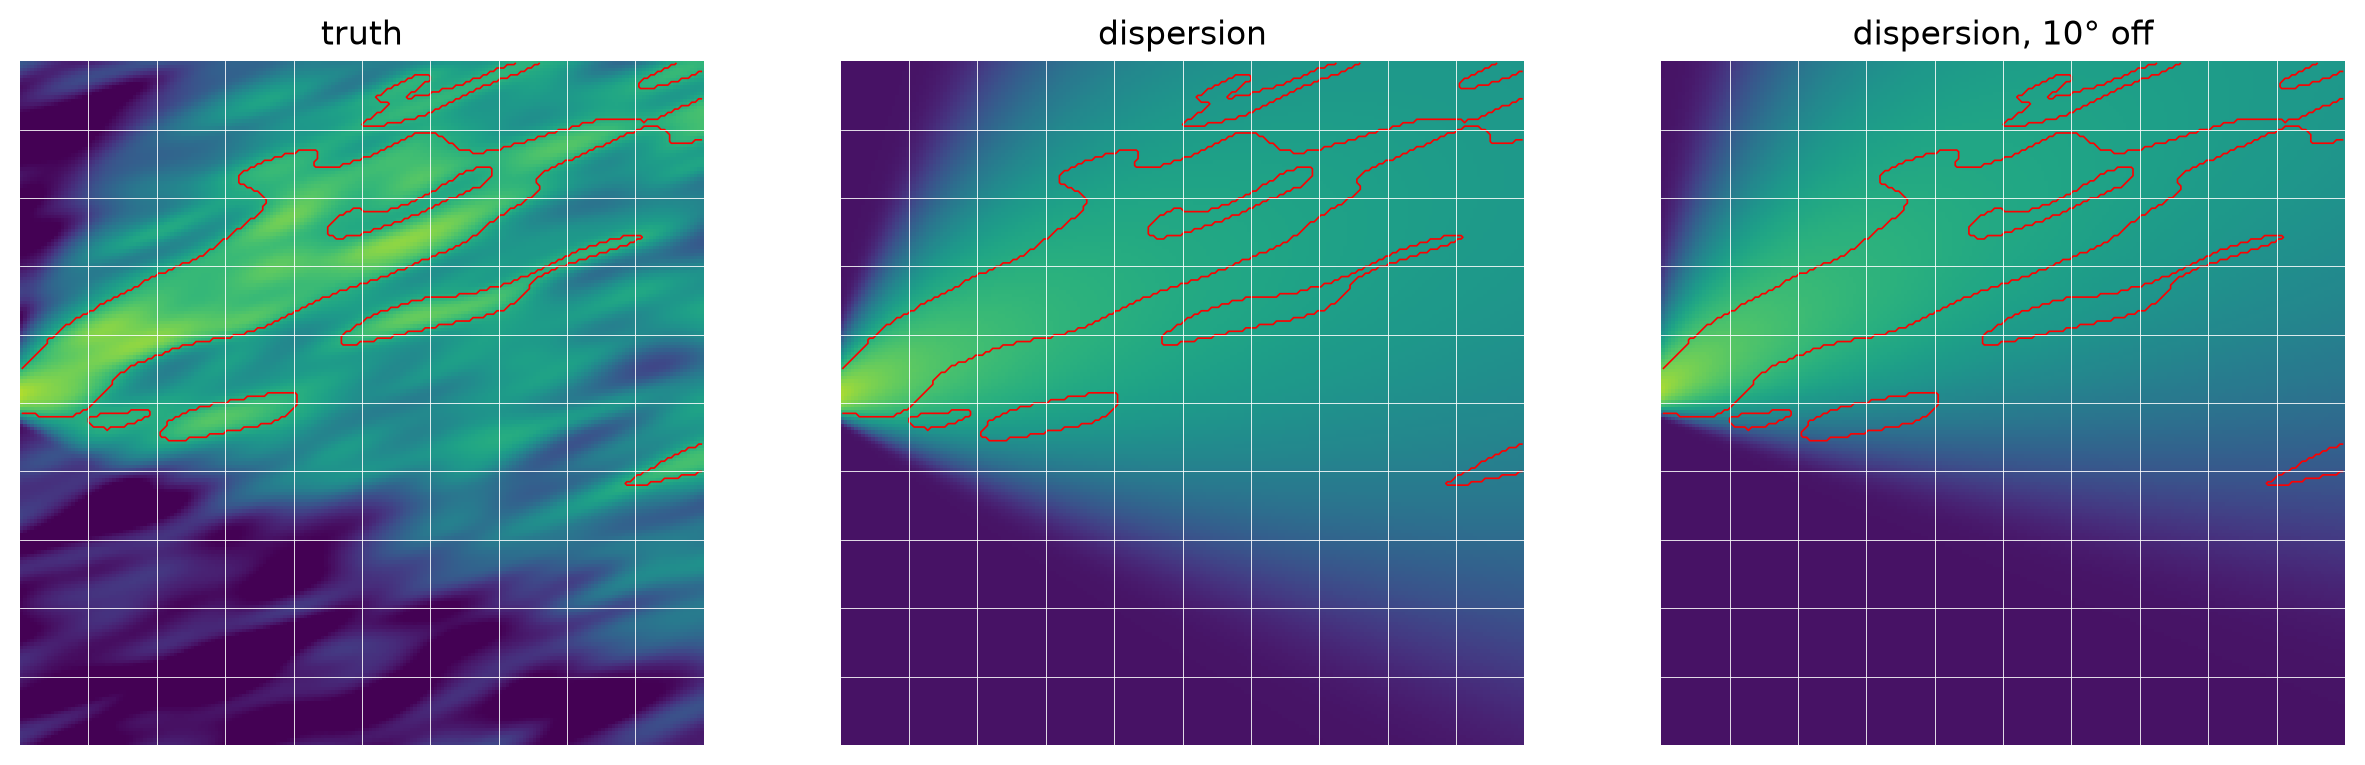

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, path) in zip(axs, [('truth', f_plume), ('dispersion', plume_priors['dispersion']), ('dispersion, 10° off', plume_priors['dispersion, 10° off'])]):
    with rasterio.open(path) as src: ax.imshow(np.log10(src.read(1)), cmap='viridis', vmin=-1.5, vmax=2.5)
    ax.contour(plume > lvl_plume, levels=[0.5], colors='r', linewidths=0.6)
    for k in range(1, 10): ax.axhline(k * 20 - 0.5, color='w', lw=0.3); ax.axvline(k * 20 - 0.5, color='w', lw=0.3)
    ax.set_title(name); ax.axis('off')

In [ ]:
def plume_strategies():
    "Baselines, `voi` without a prior, and `voi` with each plume prior at strengths 4 and 20."
    s = {'equal': cumulative_min(equal(0), 1), 'bayes': cumulative_min(bayes(lvl_plume, 0.1, 0), 1), 'voi': voi(lvl_plume),
         'oracle': cumulative_min(decision_oracle(f_plume, lvl_plume, 0.1, 0), 1)}
    for pname, fp in plume_priors.items():
        for m in [4, 20]: s[f'voi, {pname}, {m}'] = voi(lvl_plume, fname_prior=fp, strength=m)
    return s

cmp_plume = compare(Campaign(f_plume, g_plume, score=partial(decisions, level=lvl_plume)), plume_strategies(),
                    budgets=[150] * 6, seeds=range(40), summary=summarise_decisions)

Wrong decisions after rounds 1, 3 and 6, averaged over 40 seeds:

In [ ]:
cmp_plume.groupby(['strategy', 'round']).wrong.mean().unstack()[[1, 3, 6]].sort_values(6).round(1)

round,1,3,6
strategy,,,
"voi, perfect, 20",10.8,4.0,3.2
"voi, survey, 20",11.2,6.0,4.1
"voi, survey, 4",11.2,5.4,4.4
"voi, perfect, 4",11.2,5.7,4.5
"voi, dispersion, 4",14.8,7.0,5.0
oracle,16.5,5.9,5.2
"voi, dispersion, 10° off, 4",16.5,7.8,5.7
voi,16.4,7.6,5.8
equal,16.5,8.3,6.2


Standard errors are about 0.3 at round 6. Findings:

- A survey prior or a perfect prior gives the fewest wrong decisions (3.2 to 4.5 against 5.8 for `voi` without a prior), and a head start: about 11 wrong decisions after round 1 against 16.5.
- The dispersion prior with strength 4 helps a little: 5.0 against 5.8, a paired difference of 0.7 ± 0.4 over seeds. It also gives a smaller head start in round 1 (14.8).
- With the wind 10° off, the dispersion prior at strength 4 gives no gain (5.7) and no loss.
- At strength 20, both dispersion priors are worse than equal allocation (9.1 and 8.0 against 6.2). The trend has the plume's shape but not the residual patches, which here are 0.8 log units, so trusting it as much as 20 samples sends samples to the wrong units. Why the exact trend does worse than the one 10° off at this strength is not explained yet.
- `voi` without a prior is better than `bayes` here (5.8 against 6.6), unlike on `gt-02`.

A dispersion model is worth a small prior weight, about 4 samples, before a survey exists. Once a survey exists, it is the better prior.

### Placement in the plume

The comparison above places samples uniformly within units. Here the same plume is run with `Campaign`'s `placement`. The placements are uniform (`None`), `spread()`, `spread` stretched along the plume (`angle=20`, `aspect=4`, the ratio of the residual's ranges) and `spread` stretched along the wrong axis (`angle=110`). Five strategies, 40 seeds, 6 rounds of 150 samples.

In [ ]:
placements = {'uniform': None, 'spread': spread(), 'spread along plume': spread(angle=20, aspect=4),
              'spread, wrong axis': spread(angle=110, aspect=4)}
plume_subset = {k: v for k, v in plume_strategies().items() if k in ('equal', 'bayes', 'voi', 'voi, dispersion, 4', 'voi, survey, 4')}
cmp_place = pd.concat({pname: compare(Campaign(f_plume, g_plume, score=partial(decisions, level=lvl_plume), placement=pl), plume_subset,
                                      budgets=[150] * 6, seeds=range(40), summary=summarise_decisions)
                       for pname, pl in placements.items()}, names=['placement'])

Wrong decisions after round 6, mean and standard error over 40 seeds:

In [ ]:
w6 = cmp_place.xs(6, level='round').wrong.groupby(['strategy', 'placement']).agg(['mean', 'sem'])
w6['mean'].unstack()[list(placements)].round(1), w6['sem'].max().round(2)

(placement           uniform  spread  spread along plume  spread, wrong axis
 strategy                                                                   
 bayes                   6.6     5.4                 4.8                 6.2
 equal                   6.2     6.2                 5.5                 6.5
 voi                     5.8     5.4                 5.3                 5.3
 voi, dispersion, 4      5.0     4.8                 4.3                 5.2
 voi, survey, 4          4.4     4.6                 4.2                 4.6,
 np.float64(0.33))

Each standard error is up to 0.33. Paired with uniform placement on the same seeds and pooled over the five strategies, the change in wrong decisions is -0.30 ± 0.16 for `spread`, -0.78 ± 0.17 for `spread` along the plume and -0.04 ± 0.16 for the wrong axis. Findings:

- Spreading along the plume helps every strategy. The gain is largest for `bayes` (-1.8 ± 0.45), about -0.75 for equal allocation and for `voi` with the dispersion prior, and smaller than its standard error for `voi` with no prior (-0.45 ± 0.40) and with the survey prior (-0.18 ± 0.33).
- Spreading in every direction gains less, and clearly only for `bayes` (-1.2 ± 0.42).
- Spreading along the wrong axis gains nothing, as within a single unit in "Directional fields".
- `voi` with the dispersion prior and samples spread along the plume makes 4.3 wrong decisions, as few as `voi` with the survey prior and uniform placement (4.4). Before a survey exists, a dispersion model and the wind direction together match what the survey gives.
- Why `bayes` gains most is not explained yet.

`voi` still treats spread samples as random ones and counts each as one sample. Counting them as more, by an effective sample size, is not tried yet.

### Replication over plumes

The plume results above come from one field: the 40 seeds vary where samples go, not the plume. Here ten plume fields, each with its own seed, wind angle, plume spread and residual strength, check which findings hold. For each field the level is its 85% quantile, the priors are made as above (dispersion trend, trend 10° off, survey), and `spread` along the plume uses the field's own angle. Seven strategies, three placements and 20 seeds per field.

In [ ]:
rng = np.random.default_rng(100)
plume_params = pd.DataFrame({'angle': rng.uniform(-30, 45, 10).round(), 'spread': rng.uniform(0.2, 0.4, 10).round(2),
                             'sd': rng.uniform(0.5, 1.1, 10).round(2)}, index=pd.RangeIndex(10, name='field'))

def plume_setup(k, angle, width, sd):
    "Truth raster, units, level and priors for plume field `k`."
    truth = plume_field(np.random.default_rng(k), angle=angle, sd=sd, spread=width)
    f = write_raster(truth, f'../_data/synthetic/plume_{k}.tif')
    priors = {'dispersion': write_raster(plume_trend(angle, width), f'../_data/synthetic/plume_{k}_dispersion.tif'),
              'dispersion, 10° off': write_raster(plume_trend(angle + 10, width), f'../_data/synthetic/plume_{k}_dispersion_off.tif'),
              'survey': degrade(f, f'../_data/synthetic/plume_{k}_survey.tif', factor=10, noise=0.3, seed=k)}
    return f, gridder(f, nrows=10, ncols=10), float(np.quantile(truth, 0.85)), priors

def field_strategies(lvl, priors):
    "Baselines and `voi` with each prior, for one plume field."
    s = {'equal': cumulative_min(equal(0), 1), 'bayes': cumulative_min(bayes(lvl, 0.1, 0), 1), 'voi': voi(lvl)}
    for pname, fp in priors.items(): s[f'voi, {pname}, 4'] = voi(lvl, fname_prior=fp, strength=4)
    s['voi, dispersion, 20'] = voi(lvl, fname_prior=priors['dispersion'], strength=20)
    return s

rep, close_units = {}, {}
for k, (angle, width, sd) in plume_params.iterrows():
    f, g, lvl, priors = plume_setup(k, angle, width, sd)
    shares = pd.Series({i: (zonal_values(f, geom) > lvl).mean() for i, geom in g.geometry.items()})
    close_units[k] = shares.between(0.03, 0.3).sum()
    for pname, pl in {'uniform': None, 'spread': spread(), 'spread along plume': spread(angle=angle, aspect=4)}.items():
        rep[(k, pname)] = compare(Campaign(f, g, score=partial(decisions, level=lvl), placement=pl), field_strategies(lvl, priors),
                                  budgets=[150] * 6, seeds=range(20), summary=summarise_decisions)
rep = pd.concat(rep, names=['field', 'placement'])
plume_params.assign(close_units=pd.Series(close_units))

,angle,spread,sd,close_units
field,,,,
0,33.0,0.40,1.10,16
1,15.0,0.26,1.09,22
2,-8.0,0.33,0.74,21
3,-27.0,0.32,0.69,16
4,43.0,0.32,1.02,18
5,15.0,0.31,0.98,32
6,29.0,0.40,0.91,16
7,38.0,0.30,0.75,10
8,22.0,0.35,0.73,22


Wrong decisions after round 6, averaged over the seeds of each field and then over the ten fields, with the standard error between fields:

In [ ]:
per_field = rep.xs(6, level='round').wrong.groupby(['field', 'placement', 'strategy']).mean()
per_field.groupby(['strategy', 'placement']).agg(['mean', 'sem']).unstack('placement').round(2)

mean                               sem  \
placement                   spread spread along plume uniform spread   
strategy                                                               
bayes                         4.11               3.88    5.17   0.46   
equal                         5.33               5.42    5.92   0.48   
voi                           5.02               5.00    5.13   0.61   
voi, dispersion, 10° off, 4   4.50               4.28    4.75   0.52   
voi, dispersion, 20           5.46               5.15    6.68   0.82   
voi, dispersion, 4            4.27               4.17    4.65   0.52   
voi, survey, 4                4.04               4.03    4.03   0.51   

                                                        
placement                   spread along plume uniform  
strategy                                                
bayes                                     0.39    0.57  
equal                                     0.54    0.63  
voi                                       0.57    0.57  
voi, dispersion, 10° off, 4               0.50    0.54  
voi, dispersion, 20                       0.82    0.99  
voi, dispersion, 4                        0.49    0.52  
voi, survey, 4                            0.51    0.51

Paired differences between fields, for the findings of the single plume. Each row gives the mean over fields of the difference in wrong decisions, its standard error, and the number of fields (of 10) where the difference is negative:

In [ ]:
pf = per_field.unstack('strategy')
def diff(a, b, place_a='uniform', place_b='uniform'):
    "Difference in wrong decisions, strategy `a` with `place_a` minus `b` with `place_b`, per field."
    return pf.xs(place_a, level='placement')[a] - pf.xs(place_b, level='placement')[b]
checks = {
    'voi with dispersion prior (4) vs voi': diff('voi, dispersion, 4', 'voi'),
    'voi with dispersion 10° off (4) vs voi': diff('voi, dispersion, 10° off, 4', 'voi'),
    'voi with dispersion prior (20) vs equal': diff('voi, dispersion, 20', 'equal'),
    'voi with survey prior (4) vs voi': diff('voi, survey, 4', 'voi'),
    'voi vs bayes': diff('voi', 'bayes'),
    'voi vs equal': diff('voi', 'equal'),
    'spread vs uniform, all strategies': (pf.xs('spread', level='placement') - pf.xs('uniform', level='placement')).mean(axis=1),
    'spread along plume vs uniform, all strategies': (pf.xs('spread along plume', level='placement') - pf.xs('uniform', level='placement')).mean(axis=1),
    'voi, dispersion (4), along plume vs voi, survey (4), uniform': diff('voi, dispersion, 4', 'voi, survey, 4', 'spread along plume', 'uniform'),
}
pd.DataFrame({name: {'mean': d.mean(), 'sem': d.sem(), 'negative in': (d < 0).sum()} for name, d in checks.items()}).T.round(2)

,mean,sem,negative in
voi with dispersion prior (4) vs voi,-0.48,0.18,7.0
voi with dispersion 10° off (4) vs voi,-0.38,0.22,6.0
voi with dispersion prior (20) vs equal,0.76,0.49,5.0
voi with survey prior (4) vs voi,-1.10,0.26,9.0
voi vs bayes,-0.04,0.21,5.0
voi vs equal,-0.80,0.23,8.0
"spread vs uniform, all strategies",-0.51,0.25,8.0
"spread along plume vs uniform, all strategies",-0.63,0.31,7.0
"voi, dispersion (4), along plume vs voi, survey (4), uniform",0.14,0.38,3.0


Each field's mean has a standard error of about 0.3 from its 20 seeds; the standard errors here are between fields. Compared with the single plume above:

Confirmed:

- The survey prior at strength 4 lowers wrong decisions against `voi` with no prior by 1.1 ± 0.26, in 9 of 10 fields.
- The dispersion prior at strength 4 helps, by 0.48 ± 0.18, in 7 of 10 fields.
- `voi` beats equal allocation, by 0.8 ± 0.23, in 8 of 10 fields.
- Spread placement helps. Averaged over the strategies, `spread` lowers wrong decisions by 0.51 ± 0.25 (8 of 10 fields) and `spread` along the plume by 0.63 ± 0.31 (7 of 10).
- `bayes` gains most from spreading: 1.29 ± 0.34 with `spread` along the plume, in all 10 fields. `voi` gains 0.14 ± 0.43, and `voi` with the survey prior nothing.

Not confirmed:

- Spreading along the plume against spreading in every direction: 0.12 ± 0.09 fewer wrong decisions. With aspect 4 and units 20 cells wide, the direction adds little to spreading itself.
- With the wind 10° off, the single plume showed no gain from the dispersion prior. Over ten fields it helps by 0.38 ± 0.22 (6 of 10), close to the prior with the right direction.
- The dispersion prior at strength 20 is worse than equal allocation by 0.76 ± 0.49, in 5 of 10 fields only. It is harmful on some fields and harmless on others, not always harmful as on the single plume.
- `voi` against `bayes`: no difference (-0.04 ± 0.21). On the single plume `voi` was better by 0.8.
- `voi` with the dispersion prior and spread along the plume against `voi` with the survey prior and uniform placement: 0.14 ± 0.38 more wrong decisions, so close to it but not shown equal.

`bayes` with spread along the plume makes 3.9 wrong decisions, as few as `voi` with the survey prior (4.0), with no prior. `voi` hardly gains from spreading. One explanation, not tested yet: `voi` counts a spread sample as one random sample, and an effective sample count would change that.